In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_result.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)


945 rows  |  0 generation errors


,node_id,cstag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error,neighbor_group
0,94,94,Boisterous toddler board books join the phenom...,"PreS-Gr 1-This book is a fun, rhyming story ab...",0.2652,0.0112,0.1547,0.8266,0.8330,0.8298,2,8,6,1,False,1-5
1,119,119,"The Banks children, Jane and Michael, change n...","""An enchanting tale of adventure and mystery.""...",0.1067,0.0000,0.0889,0.7747,0.7928,0.7836,1,2,3,10,False,6-10
2,132,132,A festive Scarry classic now available in pict...,Theodor Seuss Geisel was more than Dr. Seuss t...,0.1515,0.0102,0.0909,0.8101,0.8072,0.8086,1,9,9,18,False,16-20


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


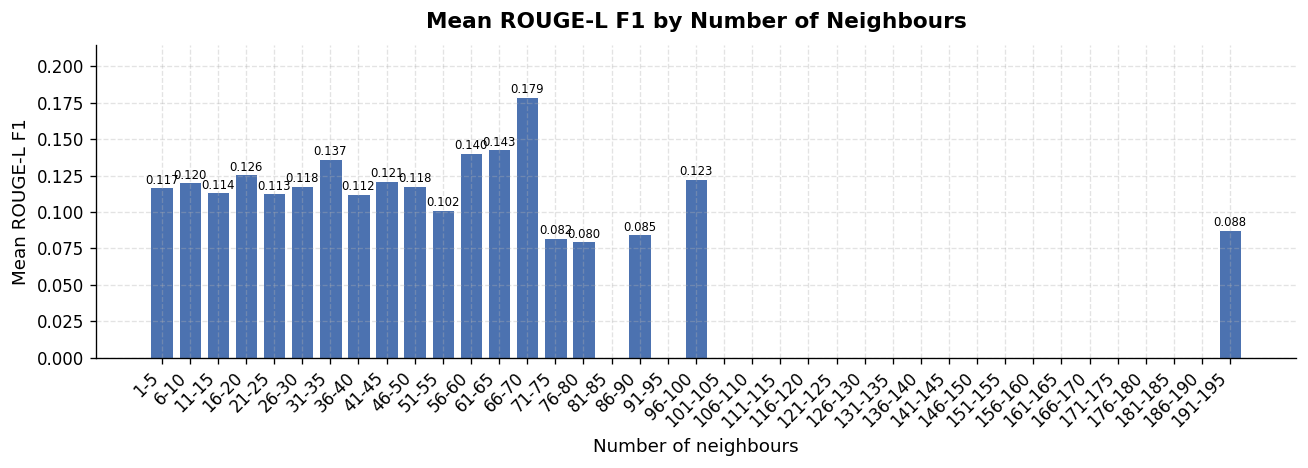

In [3]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

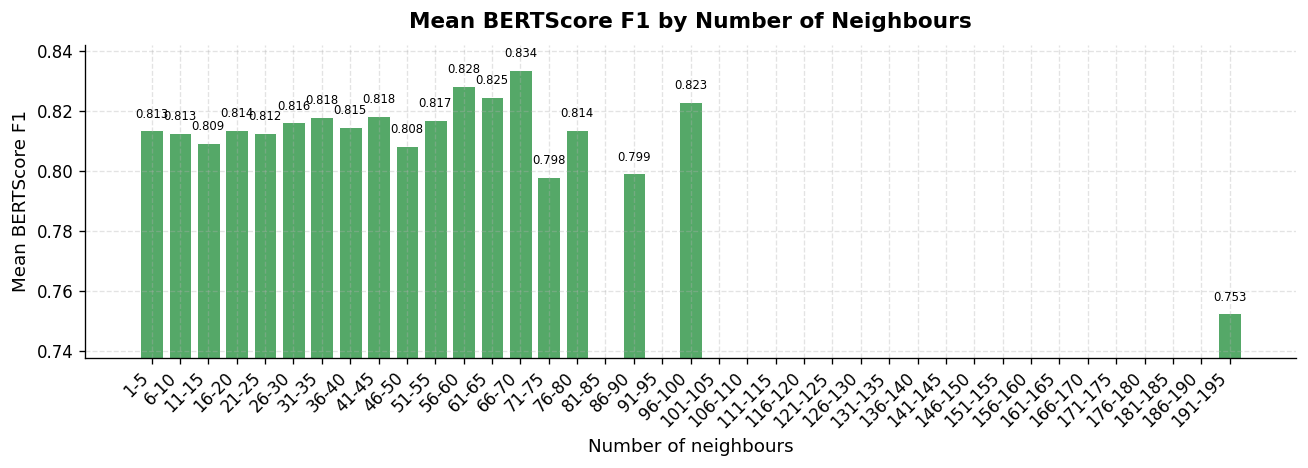

In [4]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = weighted_group_mean(df, 'bertscore_f1')
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

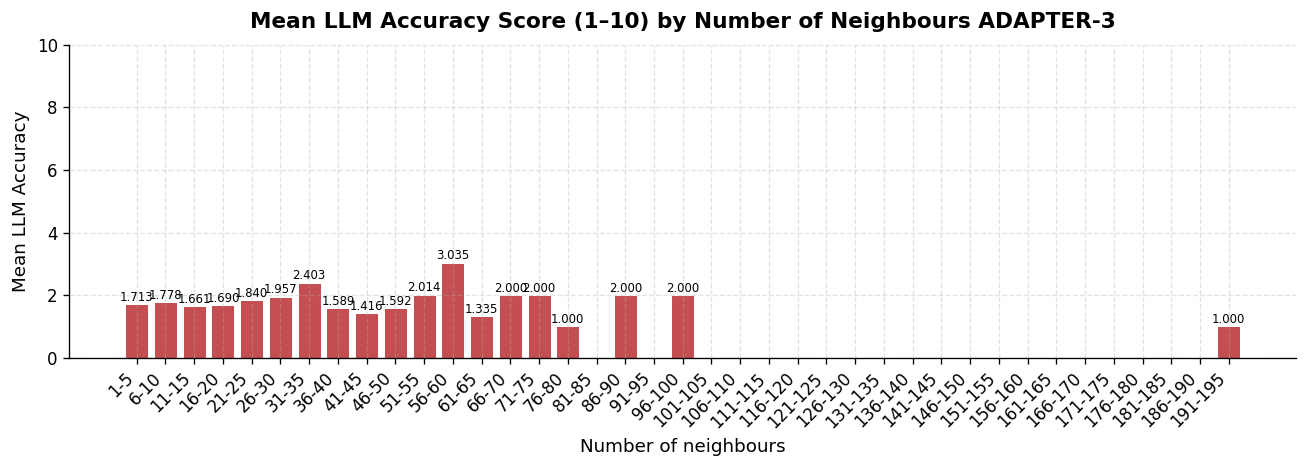

1.7322751322751322
1.0


In [5]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = weighted_group_mean(df, 'llm_accuracy')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

print(df['llm_accuracy'].mean())
print(df['llm_accuracy'].median())

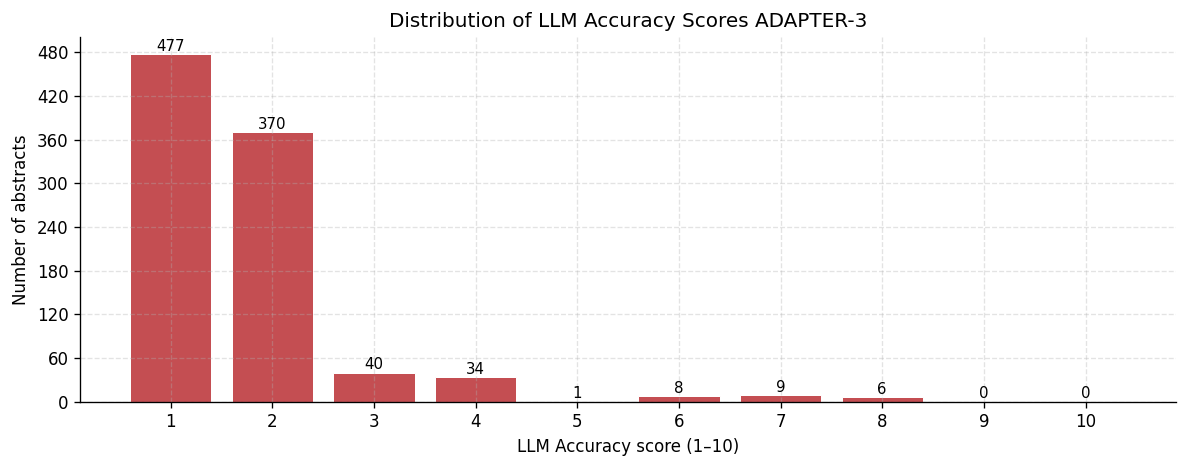

llm_accuracy
1     477
2     370
3      40
4      34
5       1
6       8
7       9
8       6
9       0
10      0
Name: count, dtype: int64

In [6]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

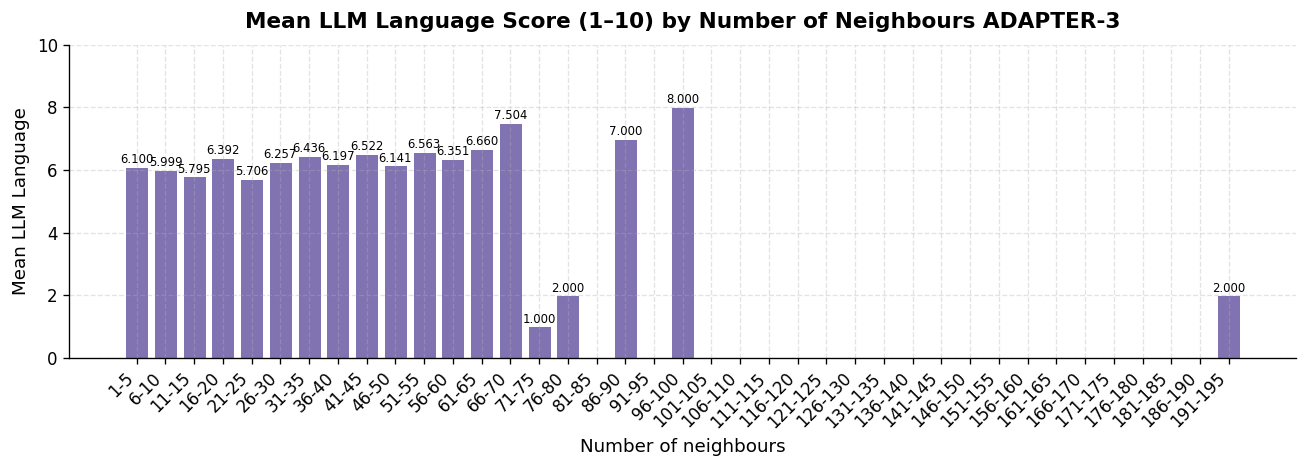

In [7]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = weighted_group_mean(df, 'llm_language')
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

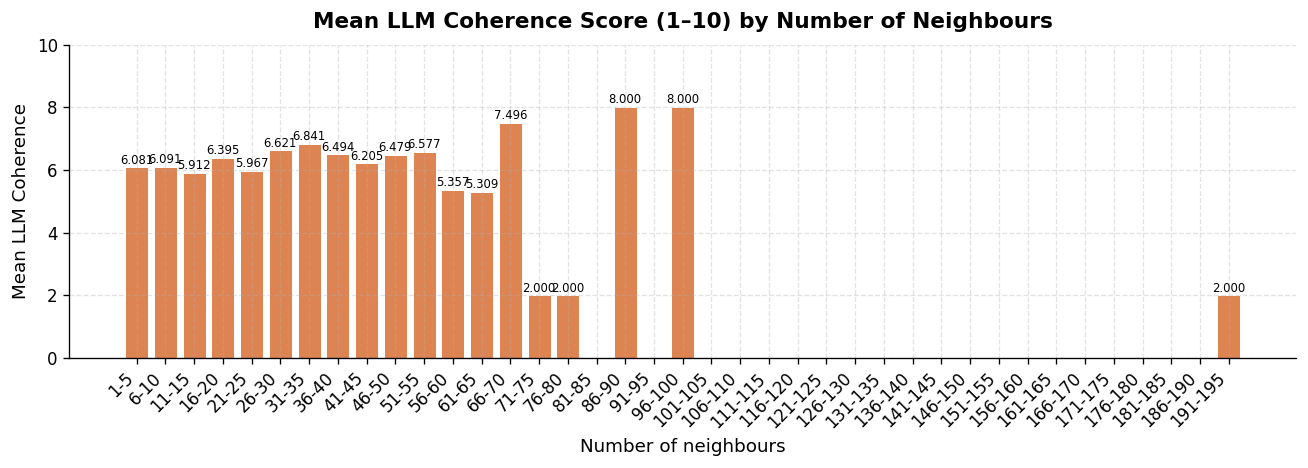

In [8]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = weighted_group_mean(df, 'llm_coherence')
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

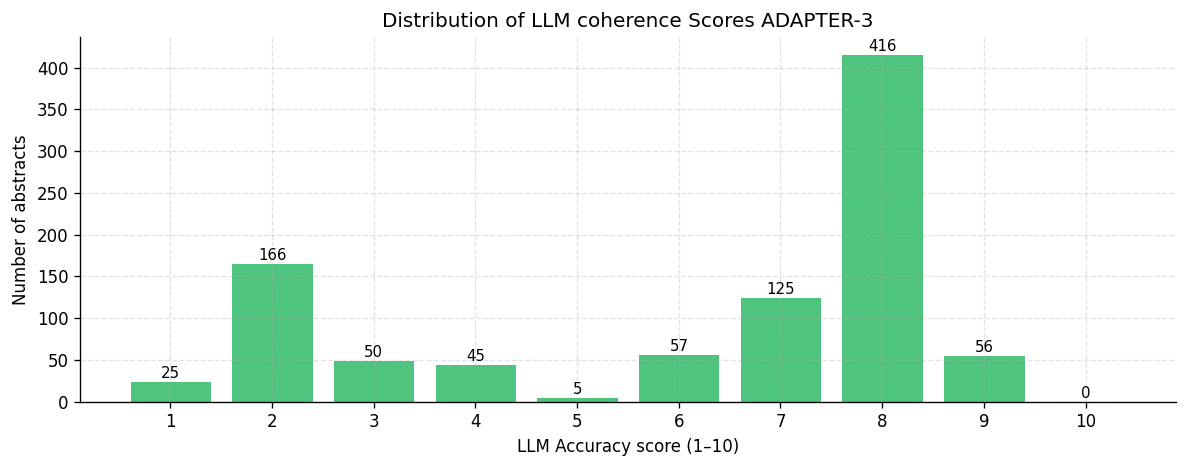

llm_coherence
1      25
2     166
3      50
4      45
5       5
6      57
7     125
8     416
9      56
10      0
Name: count, dtype: int64

In [9]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_coherence'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color="#4EC47F",
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM coherence Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

In [10]:
# ── Mean llm_accuracy excluding low-coherence (1, 2) samples ─────────────────
filtered_df = df[~df['llm_coherence'].isin([1, 2])]

print(f'Excluded {len(df) - len(filtered_df)} rows with llm_coherence in [1, 2]')
print(f'Mean llm_accuracy (all rows):      {df["llm_accuracy"].mean():.4f}')
print(f'Mean llm_accuracy (excluding 1,2): {filtered_df["llm_accuracy"].mean():.4f}')


Excluded 191 rows with llm_coherence in [1, 2]
Mean llm_accuracy (all rows):      1.7323
Mean llm_accuracy (excluding 1,2): 1.9111


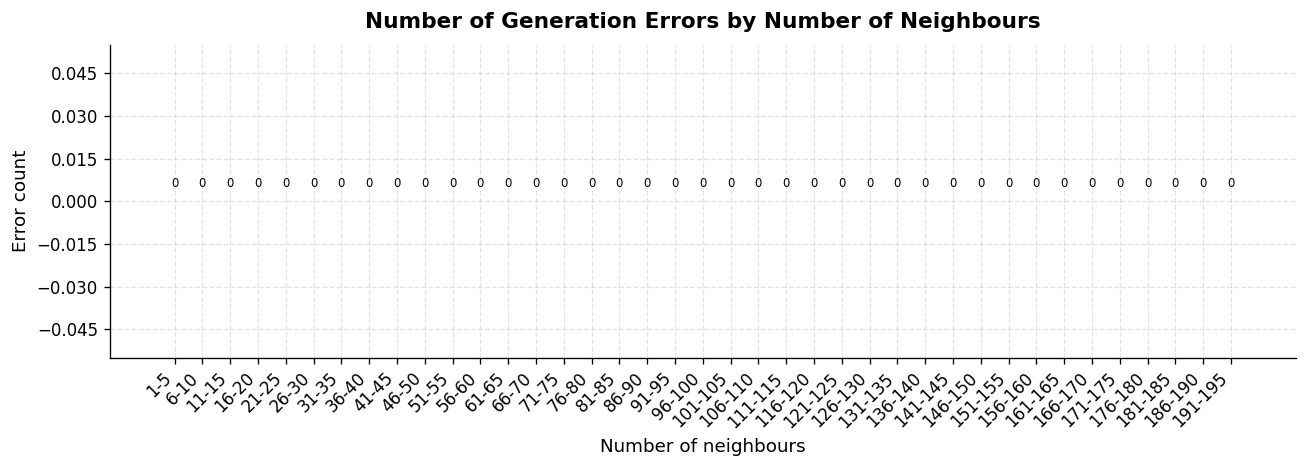

In [11]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('neighbor_group', observed=True).size().reindex(NEIGHBOR_GROUPS, fill_value=0)
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [12]:
# ── 5 examples each of llm_coherence score 1 and 2 ───────────────────────────
low_coherence_sample = (
    df[df['llm_coherence'].isin([1, 2])]
    .sort_values('llm_coherence')
    .groupby('llm_coherence', sort=True)
    .apply(lambda g: g.head(5))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_coherence']]
)

pd.set_option('display.max_colwidth', 2000)
low_coherence_sample


/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_15145/3088027966.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(5))


,node_id,original_abstract,generated_abstract,llm_coherence
0,33599,"Gr 24Everyone in the Big City knows the Ratsos. Third grader Ralphie and fifth grader Louie live with their father, Big Lou, in the animal metropolis. Their mother's unexplained absence has the family resorting to ""toughness"" as a means of survival. Big Lou tells his sons to ""hang tough."" These half-pints surmise that talking about your feelings, making friends, and being kind are only for ""softies."" They plan to show how tough they are by pulling pranks on their classmates and neighbors. But all of their antics backfire, leading to unwanted consequences. This animal protagonist tale is lighthearted and fun. The writing is straightforward and easy, while the pen-and-ink artwork is detailed. These characters are complex enough to interest newly independent readers, and the story resolution is heartfelt and solid. The father-son dynamic is realistic and honest. Young readers will feel for the family as they learn to deal with the absence of a loved one. This slender novel packs a strong message of overcoming loss through love and kindness. VERDICT A solid purchase; a chapter book that entertains and uplifts.Sada Mozer, Los Angeles Public LibraryLouie and Ralphie Ratso are determined to be as tough as their truck-driver father, but the rats efforts go hilariously awry in this funny, thoughtful, and smart chapter book...LaReau packs substantial comedy and poignant emotion into each chapter (the boys mother has been gone for a little while now), adeptly amplified by Myerss spot art.Publishers Weekly (starred review)LaReau keeps the action high and completely appropriate for readers embarking on chapter books...The humor springs from their foiled efforts and their reactions to their failures. Myers' sprightly grayscale drawings capture action and characters and add humorous details, such as the Ratsos' ""unwelcome"" mat. A nicely inventive little morality ""tail"" for newly independent readers.Kirkus ReviewsThe father-son dynamic is realistic and honest. Young readers wil...","Gr 13This is a story about a boy who loves to read. The boy is named Max, and he has a dog named Pug. Max and Pug are best friends, and they spend a lot of time together. Max loves to read, and Pug loves to play. Max is always reading, and Pug is always playing. Max is always reading about animals, and Pug is a dog. Max is always reading books about animals, and Pugs are animals. Max is always reading. Pug is always playing with his toys. Max is always reading and Pug is always reading. Max is always reading with Pug. Pug is always reading with Max. Max and Pug love to read together. Max and Pug read together. Max and his dog Pug read together. Pug and his boy Max read together. Max and the dog Pug read together, and the dog Pug and his boy read together. Max and dog Pug read together and dog Pug and his Max read together. Max reads with Pug and Pug reads with Max. Max and his dog read together and his dog and Max read together. Max loves to play with Pug, and Pug loves Max. Max and Pugs love to read together. Pugs and Max love to read together. The dog Pug and his human Max love to read together, and Max and his dog Pugs love to read. Max and Pug and Max and Pug and Pug and Max love to read. Max loves to read and Pug loves to read. Max and his dog love to read. Max is always reading to Pug. Pug loves to read with Max. Max and dog Pugs love to play and read together. Max and Max and Pug love reading. Max and Pug, Pug and Max, Max and Pug, and Pugs and Max love reading. Max and his dog, Pug, love to read. Max, Pug, and Max love to read with Pug. Max and his dog and his dog and Max love to read and play. Max and Pug play and read together. Pug loves to play and Max loves to read. Max loves Pug and Pug loves Max, and they love to read together. This is a story about a dog and a boy who love to read. Max reads with Pugs. Pugs read with Max. Max loves to read with Pugs. Pug loves to be read 

In [13]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_15145/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,36023,"Kindergarten-Grade 3Simple prose introduces two animals, a cat and a dog, that survived Hurricane Katrina in New Orleans, and, after four months of wandering, were rescued by the Best Friends Animal Society. The narrative is obviously part supposition as the original owners were never found, despite efforts to locate them. Since both pets had bobbed tails, a shelter volunteer named them Bob Cat and Bobbi, hence the book's title. It was soon discovered that Bob Cat was blind, making his survival even more amazing and underscoring the idea that the two critters relied on one another during their ordeal. The terrifying event is told about in a matter-of-fact way, with the text concentrating on the ""feel good"" aspect of the two Bobbies. The gouache illustrations, done in soft pastel shades, present realistic glimpses of the devastated city that serve as a backdrop for the animals' struggles. An afterword includes a photo and additional information. An excellent introduction to Katrina for young children, this touching animal tale memorializes a modern catastrophe and pays tribute to the many volunteers who traveled to New Orleans to help.Judith Constantinides, formerly at East Baton Rouge Parish Main Library, LA Copyright Reed Business Information, a division of Reed Elsevier Inc. All rights reserved.Neither Bobbi the dog nor Bob Cat has a tail, and some say thats what brought them together. Abandoned during the Katrina evacuations, pets Bobbi and Bob Cat wander dangerous, debris-strewn streets seeking food and water. Eventuallytaken to a rescue shelter, the Bobbies show distress when separated but remain calm when together. Workers then discover that Bob Cat is blind and that Bobbi seems to serve as his seeing-eye dog. A national news appearance ultimately results in the animals'shared adoptionin a happy new home. The descriptive, sometimes folksy prose and realistically rendered gouache illustrations accessibly convey the Bobbies experiences and mutual devotion. A...","Gr 1-3-This picture book biography of the man who invented the windmill is a bit of a stretch. The author begins with a brief introduction to the man and his invention, then moves on to a story about a boy who is inspired by the windmill to build his own. The boy's story is fictional, but it is based on the author's own childhood. The book ends with a brief note about the author's life and how it was influenced by the windmill. The illustrations are colorful and lively, and the text is simple and easy to read. The book is a bit confusing, though, as it jumps from the author's childhood to the life of the inventor and back again. The story of the boy is also a bit disjointed. The book is a good introduction to the inventor, but it is not a strong biography.-Linda L. Walkins, Mount Saint Joseph Academy, Brighton, MA(c) Copyright 2013. Library Journals LLC, a wholly owned subsidiary of Media Source, Inc. No redistribution permitted.""A story of a boy who is inspired to build a windmill after seeing one in a book. The story is based on the author’s own childhood, and the book ends with a brief biography of the inventor of the windmill. The story is a bit disjointed, but the illustrations are colorful and lively."" --School Library Journal",1
1,39114,"Grade 3-6-It is 1778 and the Revolution has come to Setauket, Long Island. Thomas Strong, son of a loyal Patriot who has been imprisoned by the Tories, tells how he is sent to search for a neighbor's whaleboat and report the location to his mother. Unknown to him, Thomas's mother then hangs specific petticoats or handkerchiefs on the clothesline as a code to pass on the information to the Patriots across the Long Island Sound. It is only when the war is over and he meets General Washington that Thomas realizes just what part his family played in the Setauket Spy Ring. Historical picture books can bring the past alive in a simple and appealing manner, bu

In [14]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


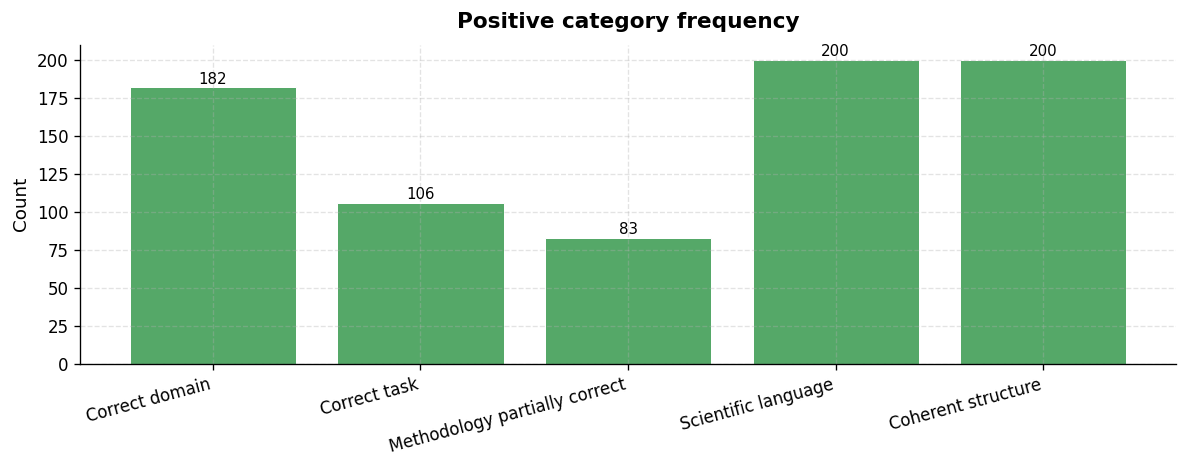

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()